<div style="border-left:6px solid #1f4e79;padding:12px 18px;background:#f3f7fb">

# CS4085 Deep Learning — Lab 7: Image Segmentation with U-Net
## 🚗 Mission: *Repair the car's vision*
**Effat College of Engineering** &nbsp;|&nbsp; Instructor: **Dr. Naila Marir**

</div>

### The story
A self-driving car has lost its vision. Its camera still works, but the network that tells it **which pixel is road, car, pedestrian or sidewalk** is broken. Your mission is to rebuild that network — a **U-Net** — level by level, and prove that the car can see again.

This task is **semantic image segmentation**: predicting a class label for **every pixel** of an image. The images come from the **CARLA self-driving car simulator**, with **13 classes** (labels 0–12).

### Learning outcomes
1. Explain how a U-Net differs from a regular CNN.
2. Build the U-Net encoder and decoder blocks in Keras.
3. Connect them with skip connections into a full U-Net.
4. Train it with sparse categorical cross-entropy for pixel-wise prediction.
5. Turn the model output into a predicted mask.

### The levels
| Level | Challenge | Points |
|---|---|---|
| 1 | 🧩 Shape puzzle — predict the size of every block | 10 |
| 2 | 🧩 Code-order puzzle + **Exercise 1** `conv_block` | 5 + 15 |
| 3 | **Exercise 2** `upsampling_block` + 🧩 parameter riddles | 15 + 10 |
| 4 | 🐞 Bug hunt + **Exercise 3** `unet_model` | 10 + 20 |
| 5 | 👾 Final boss — train the U-Net and reach the accuracy target | 15 |
| | **Total** | **100** |

### Rules of the game
1. Enter your **student ID** in the first code cell. Your puzzles are generated from it, so every student gets different numbers.
2. Each level is **locked**. When you finish a level, you get a **key** 🔑. Paste it into `enter_key(...)` at the start of the next level.
3. Stuck? Call `hint(level)`. Each level has 3 hints; each one costs 2 game points.
4. Really stuck? `skip_level(level)` opens the next level for 5 game points — so one hard level never blocks you.
5. Write code only between `### START CODE HERE` and `### END CODE HERE`, and answers only in the **ANSWER** cells. **Do not delete the first line of any graded or answer cell.**
6. Hints and skips change only your *game score*. Your **official grade** is computed by your instructor's grader, which re-tests your submitted notebook with hidden tests.

Use a **GPU runtime**: *Runtime → Change runtime type → T4 GPU*.


## 🛠️ Level 0 — Garage setup

### 0.1 Who is driving?
Type your Effat student ID between the quotes, then run the cell.

In [89]:
# ANSWER: ID
STUDENT_ID = "22208066"

### 0.2 Get the data
Your data must be in Google Drive like this (use the folders shared on Blackboard):
```
My Drive/
└── ML_Labs/
    └── Lab7/
        ├── CameraRGB/     ← images
        └── CameraSeg/     ← masks
```
Run the cell below. It connects your Drive and copies the data into Colab so training is fast.

In [90]:
LAB_DIR = '/content/drive/MyDrive/ML_Labs/Lab7'

import os, shutil
try:
    from google.colab import drive
    drive.mount('/content/drive')
    # the data may sit directly in Lab7 or inside Lab7/data
    SRC = os.path.join(LAB_DIR, 'data') if os.path.exists(os.path.join(LAB_DIR, 'data')) else LAB_DIR
    DATA_DIR = '/content/data'
    if not os.path.exists(DATA_DIR):
        os.makedirs(DATA_DIR)
        for sub in ['CameraRGB', 'CameraSeg', 'CameraMask']:
            if os.path.exists(os.path.join(SRC, sub)):
                shutil.copytree(os.path.join(SRC, sub), os.path.join(DATA_DIR, sub))
except ImportError:            # not running in Colab: use a local ./data folder
    DATA_DIR = './data'

MASK_FOLDER = 'CameraMask' if os.path.exists(os.path.join(DATA_DIR, 'CameraMask')) else 'CameraSeg'
print('Images:', len(os.listdir(os.path.join(DATA_DIR, 'CameraRGB'))))
print('Masks :', len(os.listdir(os.path.join(DATA_DIR, MASK_FOLDER))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Images: 1010
Masks : 1000


### 0.3 Import the libraries

In [91]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dropout, Conv2DTranspose, concatenate

print('TensorFlow', tf.__version__, '| GPU:', len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow 2.21.0 | GPU: True


### 0.4 Start the game engine
This cell holds the game: keys, hints, checks and the scoreboard. It is folded on purpose — **run it, do not edit it.** It prints your mission briefing.

In [92]:
# @title 🎮 Game engine — run this cell, do not edit it
import hashlib, json

_SALT = "CS4085-L7-UNET"
_SIZES = [(96, 128), (64, 96), (128, 160), (80, 112), (112, 144)]
_FILTERS = [16, 24, 32]
_HASHES = json.loads(r'''{"L1": {"0": {"cblock1": "824db555ced061e5", "cblock2": "c9d0adb7757807c6", "cblock3": "cb0c902a6cf6269f", "cblock4": "b1951b84ec0c4da9", "cblock5": "cc2aa07b43d8da77", "ublock6": "7f97fd512b4d0c1c", "ublock7": "655ac2e1812e1e5a", "ublock8": "311de2fcddb45335", "ublock9": "fc094a65b11412a6", "output": "2c1cc2be2cedc00d"}, "1": {"cblock1": "e7325c91edea0bd7", "cblock2": "69092e43b9c1d394", "cblock3": "ff6fc59633626e37", "cblock4": "3986517cdff49794", "cblock5": "c46441fca09083c9", "ublock6": "e4bcdba59eef06db", "ublock7": "a1b10ccfdca9d308", "ublock8": "b47fee751b12e193", "ublock9": "02bfbec9a4a191c8", "output": "21c378c4dc267433"}, "2": {"cblock1": "651e13069b178100", "cblock2": "4f35f75d0a19291f", "cblock3": "5a1d4fed140f1bd4", "cblock4": "a3d4adc9c196ce7f", "cblock5": "f6468c22b727749a", "ublock6": "8081084f2dfb3640", "ublock7": "6ea5d3b0e5ca144d", "ublock8": "73cf022b3cf7a84b", "ublock9": "c96631fc99d4231a", "output": "dcfd63c713b5b2e1"}, "3": {"cblock1": "600232b4f65ddadc", "cblock2": "9890825712c7cda7", "cblock3": "566c354a8985a193", "cblock4": "805afab6ec854bb2", "cblock5": "7ed6732f474facff", "ublock6": "42218d593af7ed0d", "ublock7": "b16b677a4624a7b2", "ublock8": "b640488b6a79764a", "ublock9": "6132f01594bdb207", "output": "984632b0fa8f2d63"}, "4": {"cblock1": "5452e426ebadedbe", "cblock2": "9c902adf6e2ee3a2", "cblock3": "98a1e0b3cebd2122", "cblock4": "78663e0f4528d91a", "cblock5": "59d464ef5df9ecf9", "ublock6": "5e17b2dca53e8601", "ublock7": "78d16aa2900aee49", "ublock8": "23196c34fe94b5c0", "ublock9": "ca8ab92d2aff7843", "output": "14717511e9e1f20f"}, "5": {"cblock1": "09c3036cd6371617", "cblock2": "65a98fffdc92abc9", "cblock3": "266e699263dc6186", "cblock4": "56665520e591d153", "cblock5": "1abff6ca9f929873", "ublock6": "1f1e022e270e2d69", "ublock7": "7b82514d06b733c2", "ublock8": "285f4322e851604f", "ublock9": "fb1afa96647a7666", "output": "6fe9cebffff5c542"}, "6": {"cblock1": "e07b1e62a3682252", "cblock2": "0af61d2d885683db", "cblock3": "d6e1155de0056cc4", "cblock4": "67435c41c1e1561a", "cblock5": "99b2f04f192d6432", "ublock6": "9c2e933a3982e943", "ublock7": "a83c2519bea86bc4", "ublock8": "c6e7da4e6f4c12b2", "ublock9": "d6dd0d3bdac8dd59", "output": "61a25bb5117b4900"}, "7": {"cblock1": "0b726da7200630e1", "cblock2": "74462edbe55588fb", "cblock3": "ec2f74538ca07da3", "cblock4": "09accbd600f6a1ce", "cblock5": "d1e1da6fa575c303", "ublock6": "c7be58c8a9499b1e", "ublock7": "32d5952ca072ec94", "ublock8": "28099c5e66f57c2c", "ublock9": "1d0cf3b549e35d8b", "output": "0a8c78a6979e7b5c"}, "8": {"cblock1": "d3c641c7c518b19c", "cblock2": "7026bb6f5f79c40a", "cblock3": "702b766f708c378c", "cblock4": "c516e7837c11a43a", "cblock5": "e4558d084d0c650a", "ublock6": "a3afe9c565dd044f", "ublock7": "b567e5d6994f5f1e", "ublock8": "86f8cb705d0ce655", "ublock9": "11cbaca41c706c16", "output": "b14f5f1f481548d2"}, "9": {"cblock1": "c4dbfc6777972c86", "cblock2": "dd9ced8711ae48d1", "cblock3": "0fd62dc1b674c41b", "cblock4": "d4d183fedd081b28", "cblock5": "0628d4b93390b03f", "ublock6": "bf104178bf85f5aa", "ublock7": "f365946ab2ed9c09", "ublock8": "0dafb18dd1a90312", "ublock9": "5e869c7d2765adf9", "output": "9beed0a04efacd6f"}, "10": {"cblock1": "6205710e6db24b34", "cblock2": "dc32cc2c24989ea8", "cblock3": "5b472ed07004984c", "cblock4": "11ec5f669622f92e", "cblock5": "b95bd73e2e0a7045", "ublock6": "28fc245b66e4a8d9", "ublock7": "63c308863f722e5e", "ublock8": "c7399583251617bb", "ublock9": "a17f1b026d03d53b", "output": "6d68352195bf7605"}, "11": {"cblock1": "c2cedf04bf92a82e", "cblock2": "5abd2eb95c111d05", "cblock3": "c728f6a1697c0af0", "cblock4": "5743377776faec65", "cblock5": "64d9b1f9d29c676c", "ublock6": "cb4e21d2dc444a8e", "ublock7": "4c0d9d854294c552", "ublock8": "0f97b4ebefcb6b01", "ublock9": "1af34d5c27ed63a8", "output": "018be46434f3c172"}, "12": {"cblock1": "b15874bc31d1c2e2", "cblock2": "c5fed5444a596685", "cblock3": "9a24d229b31504c1", "cblock4": "51a8289973cb8095", "cblock5": "04b108e910b6878a", "ublock6": "30950c44bf073b1c", "ublock7": "61c0642e060269aa", "ublock8": "1720205667c0fde2", "ublock9": "2f11ac27c61d95ff", "output": "3a8ed4c81430fc9d"}, "13": {"cblock1": "1ebfa8e416a5eff4", "cblock2": "118752cc5ca1ca96", "cblock3": "9af0f5f0eb7e8f9c", "cblock4": "b34f23561276e5cf", "cblock5": "216b75cdec170f47", "ublock6": "0ffbe233901db0b4", "ublock7": "285c1f885e5518fb", "ublock8": "cbf0639cf45cc575", "ublock9": "ea985240c8c62651", "output": "ab952b8bc7307f8d"}, "14": {"cblock1": "b237ee3385f4bec4", "cblock2": "70d6bbbe23d80001", "cblock3": "aca863b14dc3bb39", "cblock4": "858213ac7c431397", "cblock5": "532dd9fa42f4c67b", "ublock6": "87289c564f02f412", "ublock7": "6c5951c6c0ae2da6", "ublock8": "6f6cee93c68ae9e9", "ublock9": "9b30c0238bdbb9eb", "output": "b12a4e9cea9c1280"}}, "L2": {"0": {"shown": [["A", "skip_connection = conv"], ["B", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["C", "conv = Dropout(dropout_prob)(inputs)"], ["D", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["E", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["F", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["G", "return next_layer, skip_connection"], ["H", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"]], "valid": ["cfa99b62867118d4", "e7d2fa3446c03295"]}, "1": {"shown": [["A", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["B", "return next_layer, skip_connection"], ["C", "skip_connection = conv"], ["D", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["E", "conv = Dropout(dropout_prob)(inputs)"], ["F", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["G", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["H", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"]], "valid": ["6dd30016518af0b0", "ed32601b270fb9fd"]}, "2": {"shown": [["A", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["B", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["C", "skip_connection = conv"], ["D", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["E", "return next_layer, skip_connection"], ["F", "conv = Dropout(dropout_prob)(inputs)"], ["G", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["H", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"]], "valid": ["b68f41feea623344", "2fc0a0f0b853d453"]}, "3": {"shown": [["A", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["B", "return next_layer, skip_connection"], ["C", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["D", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["E", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["F", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["G", "skip_connection = conv"], ["H", "conv = Dropout(dropout_prob)(inputs)"]], "valid": ["bc90dd8d0dfbaf27", "57e26ef775d2afc5"]}, "4": {"shown": [["A", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["B", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["C", "conv = Dropout(dropout_prob)(inputs)"], ["D", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["E", "skip_connection = conv"], ["F", "return next_layer, skip_connection"], ["G", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["H", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"]], "valid": ["cb35dcd795d71040", "7bc7ac576fb138f3"]}, "5": {"shown": [["A", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["B", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["C", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["D", "return next_layer, skip_connection"], ["E", "skip_connection = conv"], ["F", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["G", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["H", "conv = Dropout(dropout_prob)(inputs)"]], "valid": ["b4214b4bafb6ecbe", "a26823cf54742258"]}, "6": {"shown": [["A", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["B", "conv = Dropout(dropout_prob)(inputs)"], ["C", "skip_connection = conv"], ["D", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["E", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["F", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["G", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["H", "return next_layer, skip_connection"]], "valid": ["77a5d6c09925cdb9", "a1ea93211f7fcaa3"]}, "7": {"shown": [["A", "return next_layer, skip_connection"], ["B", "conv = Dropout(dropout_prob)(inputs)"], ["C", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["D", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["E", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["F", "skip_connection = conv"], ["G", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["H", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"]], "valid": ["14f8c7ab5bc319d0", "25b3f8fe236d26c4"]}, "8": {"shown": [["A", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["B", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["C", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["D", "skip_connection = conv"], ["E", "return next_layer, skip_connection"], ["F", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["G", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["H", "conv = Dropout(dropout_prob)(inputs)"]], "valid": ["91c4d714aa13da8b", "9c711a66064c26ca"]}, "9": {"shown": [["A", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["B", "conv = Dropout(dropout_prob)(inputs)"], ["C", "skip_connection = conv"], ["D", "return next_layer, skip_connection"], ["E", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["F", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["G", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["H", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"]], "valid": ["e4a7518308ff1eab", "e132943bb968c396"]}, "10": {"shown": [["A", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["B", "return next_layer, skip_connection"], ["C", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["D", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["E", "conv = Dropout(dropout_prob)(inputs)"], ["F", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["G", "skip_connection = conv"], ["H", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"]], "valid": ["9978422911d6d5ef", "753b9458ca7a490d"]}, "11": {"shown": [["A", "conv = Dropout(dropout_prob)(inputs)"], ["B", "skip_connection = conv"], ["C", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["D", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["E", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["F", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["G", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["H", "return next_layer, skip_connection"]], "valid": ["2b3e33eae34708cd", "8d3d592aa8bb38e1"]}, "12": {"shown": [["A", "skip_connection = conv"], ["B", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["C", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["D", "conv = Dropout(dropout_prob)(inputs)"], ["E", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["F", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["G", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["H", "return next_layer, skip_connection"]], "valid": ["9f69bf60ca9fa717", "65e97ee76cb63744"]}, "13": {"shown": [["A", "return next_layer, skip_connection"], ["B", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["C", "skip_connection = conv"], ["D", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"], ["E", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["F", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["G", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["H", "conv = Dropout(dropout_prob)(inputs)"]], "valid": ["43fb72b420ad8bf4", "48a398685c7c41cf"]}, "14": {"shown": [["A", "return next_layer, skip_connection"], ["B", "skip_connection = conv"], ["C", "skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)"], ["D", "next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv"], ["E", "conv = Dropout(dropout_prob)(inputs)"], ["F", "if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)"], ["G", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)"], ["H", "conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)"]], "valid": ["dbb4956b9e4bd99e", "c83105dd91f15fbd"]}}, "L3": {"0": {"R1": "5bc34c758d45e453", "R2": "fb65142bd4952670", "R3": "02ca1b852b29ff16"}, "1": {"R1": "2c64f1c2f28b0ef2", "R2": "ff416d8562744ffc", "R3": "ea35f48cbf9d3575"}, "2": {"R1": "c71aac90505fceda", "R2": "482ab8578190b9a1", "R3": "60bd3e1c75619296"}, "3": {"R1": "bdb114bd140e47b1", "R2": "a0148d9fbd1e50fc", "R3": "752ab9ba759dc917"}, "4": {"R1": "aa8f07066ccf97dd", "R2": "63d9b31a6844eb4c", "R3": "61c6fe6d2d40fffe"}, "5": {"R1": "53d98432d3cfb477", "R2": "b24af889a4ca588f", "R3": "0605b7fb655a2197"}, "6": {"R1": "10e52415d1211184", "R2": "91cbfef5a7c8429a", "R3": "21a43b7dfb6240eb"}, "7": {"R1": "e0e49174f65e4e38", "R2": "103326153205b9b3", "R3": "30b75f004f2c4d02"}, "8": {"R1": "25489029576304ab", "R2": "98431959cc74317c", "R3": "62a2005fa5ff4a6f"}, "9": {"R1": "a2098df069dd119b", "R2": "ec329aa6b0fad86b", "R3": "5aa6758fef250e99"}, "10": {"R1": "3300c4a19cb83b30", "R2": "84bbd71e235ab2eb", "R3": "4b20f1e1939834bb"}, "11": {"R1": "e860c0dfd97a525e", "R2": "1a357760c2d99473", "R3": "b82b8c9660bd6881"}, "12": {"R1": "600e8f91d1ab31f7", "R2": "d5ec23c2a59f8bf8", "R3": "c3ca34c18551eb94"}, "13": {"R1": "c8a4fc8215771215", "R2": "7f7c7469d000cb43", "R3": "64a56929efb3636e"}, "14": {"R1": "2ab58b0b69759be9", "R2": "5390af181324e2d7", "R3": "32b1bf4598067dde"}}, "L4_layers": [["a110239eb57f0d67", "18cd919c45731c64", "8a101ad95a9b887b", "f6305b728e9c593c"], ["a110239eb57f0d67", "18cd919c45731c64", "6573e55b2753f537", "f6305b728e9c593c"], ["58f88d122fc1268e", "1d99b92326148a97", "332afd0fa6c8dea0", "d81d38ada4a0e9ed"], ["a110239eb57f0d67", "a1ecfa14f214d41b", "a7febb71353d9cc4", "f6305b728e9c593c"], ["a110239eb57f0d67", "a1ecfa14f214d41b", "44edae844e51f935", "f6305b728e9c593c"], ["58f88d122fc1268e", "8a82812135698578", "332afd0fa6c8dea0", "d81d38ada4a0e9ed"], ["a110239eb57f0d67", "02d70d94e4ee1f88", "5b92d20be45056df", "f6305b728e9c593c"], ["a110239eb57f0d67", "02d70d94e4ee1f88", "a16b2167b2fe4447", "f6305b728e9c593c"], ["0b73fd0b906e1e76", "02d70d94e4ee1f88", "332afd0fa6c8dea0", "503658cf54d912ba"], ["6eefe54c4ee33148", "a1ecfa14f214d41b", "5277b381ee857647", "1006c0ddee2b22d6"], ["f7777c910b61d92d", "6368c3579f0c3daf", "332afd0fa6c8dea0", "1006c0ddee2b22d6"], ["a110239eb57f0d67", "a1ecfa14f214d41b", "5277b381ee857647", "f6305b728e9c593c"], ["a110239eb57f0d67", "a1ecfa14f214d41b", "44edae844e51f935", "f6305b728e9c593c"], ["6eefe54c4ee33148", "18cd919c45731c64", "f2cbcfe84851f679", "1006c0ddee2b22d6"], ["f7777c910b61d92d", "c3ba4e0cdd72b38b", "332afd0fa6c8dea0", "1006c0ddee2b22d6"], ["a110239eb57f0d67", "18cd919c45731c64", "f2cbcfe84851f679", "f6305b728e9c593c"], ["a110239eb57f0d67", "18cd919c45731c64", "6573e55b2753f537", "f6305b728e9c593c"], ["a110239eb57f0d67", "8080a2d03fc19410", "4db708d3d9760172", "59eab45096cbcb86"]], "L4_bugs": "78bf47bdde9e7f21"}''')
_EXPECTED = json.loads(r'''{"ex1a": [["Conv2D", [null, 96, 128, 32], 896, "same", "relu", "HeNormal"], ["Conv2D", [null, 96, 128, 32], 9248, "same", "relu", "HeNormal"], ["MaxPooling2D", [null, 48, 64, 32], 0, [2, 2]]], "ex1b": [["Conv2D", [null, 96, 128, 1024], 28672, "same", "relu", "HeNormal"], ["Conv2D", [null, 96, 128, 1024], 9438208, "same", "relu", "HeNormal"], ["Dropout", [null, 96, 128, 1024], 0, 0.1], ["MaxPooling2D", [null, 48, 64, 1024], 0, [2, 2]]], "ex2": [["Conv2DTranspose", [null, 24, 32, 32], 73760], ["Concatenate", [null, 24, 32, 160], 0], ["Conv2D", [null, 24, 32, 32], 46112, "same", "relu", "HeNormal"], ["Conv2D", [null, 24, 32, 32], 9248, "same", "relu", "HeNormal"]], "ex3": [["Conv2D", [null, 96, 128, 32], 896, "same", "relu", "HeNormal"], ["Conv2D", [null, 96, 128, 32], 9248, "same", "relu", "HeNormal"], ["MaxPooling2D", [null, 48, 64, 32], 0, [2, 2]], ["Conv2D", [null, 48, 64, 64], 18496, "same", "relu", "HeNormal"], ["Conv2D", [null, 48, 64, 64], 36928, "same", "relu", "HeNormal"], ["MaxPooling2D", [null, 24, 32, 64], 0, [2, 2]], ["Conv2D", [null, 24, 32, 128], 73856, "same", "relu", "HeNormal"], ["Conv2D", [null, 24, 32, 128], 147584, "same", "relu", "HeNormal"], ["MaxPooling2D", [null, 12, 16, 128], 0, [2, 2]], ["Conv2D", [null, 12, 16, 256], 295168, "same", "relu", "HeNormal"], ["Conv2D", [null, 12, 16, 256], 590080, "same", "relu", "HeNormal"], ["Dropout", [null, 12, 16, 256], 0, 0.3], ["MaxPooling2D", [null, 6, 8, 256], 0, [2, 2]], ["Conv2D", [null, 6, 8, 512], 1180160, "same", "relu", "HeNormal"], ["Conv2D", [null, 6, 8, 512], 2359808, "same", "relu", "HeNormal"], ["Dropout", [null, 6, 8, 512], 0, 0.3], ["Conv2DTranspose", [null, 12, 16, 256], 1179904], ["Concatenate", [null, 12, 16, 512], 0], ["Conv2D", [null, 12, 16, 256], 1179904, "same", "relu", "HeNormal"], ["Conv2D", [null, 12, 16, 256], 590080, "same", "relu", "HeNormal"], ["Conv2DTranspose", [null, 24, 32, 128], 295040], ["Concatenate", [null, 24, 32, 256], 0], ["Conv2D", [null, 24, 32, 128], 295040, "same", "relu", "HeNormal"], ["Conv2D", [null, 24, 32, 128], 147584, "same", "relu", "HeNormal"], ["Conv2DTranspose", [null, 48, 64, 64], 73792], ["Concatenate", [null, 48, 64, 128], 0], ["Conv2D", [null, 48, 64, 64], 73792, "same", "relu", "HeNormal"], ["Conv2D", [null, 48, 64, 64], 36928, "same", "relu", "HeNormal"], ["Conv2DTranspose", [null, 96, 128, 32], 18464], ["Concatenate", [null, 96, 128, 64], 0], ["Conv2D", [null, 96, 128, 32], 18464, "same", "relu", "HeNormal"], ["Conv2D", [null, 96, 128, 32], 9248, "same", "relu", "HeNormal"], ["Conv2D", [null, 96, 128, 32], 9248, "same", "relu", "HeNormal"], ["Conv2D", [null, 96, 128, 13], 429, "same", "linear", "GlorotUniform"]]}''')
BOSS_TARGET = 0.85          # validation pixel accuracy needed to defeat the boss

def _H(*p): return hashlib.sha256("|".join([_SALT] + [str(x) for x in p]).encode()).hexdigest()[:16]
def _nid(): return str(STUDENT_ID).strip().upper()
def _idx(): return int(hashlib.sha256(_nid().encode()).hexdigest(), 16) % 15
def _cfg():
    i = _idx(); return _SIZES[i % 5] + (_FILTERS[i // 5],)
def _key(level): return _H("KEY", _nid(), level)[:6].upper()
def _sstr(v):
    try: return "x".join(str(int(x)) for x in v)
    except Exception: return str(v)

_POINTS = {"L1": 10, "L2_order": 5, "ex1": 15, "ex2": 15, "L3": 10, "bug": 10, "ex3": 20, "boss": 15}
_NAMES = {"L1": "Level 1 · Shape puzzle", "L2_order": "Level 2 · Code-order puzzle", "ex1": "Level 2 · conv_block",
          "ex2": "Level 3 · upsampling_block", "L3": "Level 3 · Parameter riddles", "bug": "Level 4 · Bug hunt",
          "ex3": "Level 4 · unet_model", "boss": "Level 5 · Final boss"}
_HINTS = {
 1: ["Each encoder step halves H and W and doubles the channels.",
     "The bottleneck (cblock5) has no pooling, so it stays at H/16 × W/16.",
     "Each decoder step doubles H and W and halves the channels. The output has 13 channels — one per class."],
 2: ["Two of the eight lines are traps: they never appear in the correct block.",
     "Pooling is applied to next_layer only. The skip connection keeps the full-size tensor.",
     "Order: two convolutions → dropout → pooling and skip (either order) → return."],
 3: ["Conv2DTranspose parameters = k × k × (input channels) × filters + filters (one bias per filter).",
     "In ublock7 the input comes from ublock6 (8·n_filters channels) and the layer has 4·n_filters filters.",
     "Concatenation adds channels: up (2·n_filters) + skip (2·n_filters), at half the image height and width. The 1×1 output conv has n_filters × 13 weights + 13 biases."],
 4: ["Run mini_unet: the error message shows where the shapes stop matching — but the bug may be earlier.",
     "The encoder passes the pooled output [0] to the next block; the skip [1] goes to the decoder.",
     "The decoder halves the filters at every step, and the last layer must output raw scores (logits) because the loss uses from_logits=True."],
 5: ["The boss uses your own unet_model, so all earlier levels must pass.",
     "If accuracy is low, check that masks are read from the red channel and resized with 'nearest'.",
     "If time allows, train for more epochs (20–25)."],
}
_S = {"unlocked": {1}, "earned": {}, "hints": {}, "skipped": set(), "done": set()}

def _require(level):
    if level not in _S["unlocked"]:
        print(f"🔒 Level {level} is locked. Finish Level {level-1} to get its key, "
              f"or use skip_level({level}) (costs 5 game points).")
        return False
    return True

def _award(item, pts):
    _S["earned"][item] = max(_S["earned"].get(item, 0), pts)

def _give_key(level):
    if level in _S["done"]: return
    _S["done"].add(level)
    print(f"\n🏁 LEVEL {level} COMPLETE!")
    if level < 5:
        print(f"🔑 Key for Level {level+1}:  {_key(level+1)}   → paste it into enter_key({level+1}, '...')")

def start():
    if not str(STUDENT_ID).strip() or "YOUR" in _nid():
        raise ValueError("Set STUDENT_ID to your Effat student ID first, then run this cell again.")
    h, w, f = _cfg()
    print("🚗 MISSION: Repair the car's vision")
    print(f"Driver ID: {_nid()}")
    print(f"Your test camera (for the puzzles): {h} × {w} pixels, 3 colour channels.   Your puzzle U-Net uses n_filters = {f}.")
    print("(The real training in Level 5 uses the standard 96 × 128 images and n_filters = 32 for everyone.)")
    print("Levels 1–5 are waiting. Level 1 is unlocked. Good luck, engineer!")

def enter_key(level, key):
    if str(key).strip().upper() == _key(level):
        _S["unlocked"].add(level); print(f"🔓 Level {level} unlocked!")
    else:
        print(f"❌ That key does not open Level {level}. Finish Level {level-1} to get it.")

def skip_level(level):
    _S["unlocked"].add(level); _S["skipped"].add(level)
    print(f"⏭️  Level {level} unlocked by skipping (−5 game points). Your instructor's grader still checks every level.")

def hint(level):
    n = _S["hints"].get(level, 0)
    if n >= 3: print("No more hints for this level."); return
    _S["hints"][level] = n + 1
    print(f"💡 Hint {n+1}/3 for Level {level} (−2 game points): {_HINTS[level][n]}")

# ---------------- layer checks
def layer_summary(model):
    rows = []
    for layer in model.layers:
        name = layer.__class__.__name__
        if name == 'InputLayer':
            continue
        row = [name, tuple(layer.output.shape), layer.count_params()]
        if isinstance(layer, Conv2D) and not isinstance(layer, Conv2DTranspose):
            row += [layer.padding, layer.activation.__name__, layer.kernel_initializer.__class__.__name__]
        if isinstance(layer, MaxPooling2D):
            row.append(tuple(layer.pool_size))
        if isinstance(layer, Dropout):
            row.append(layer.rate)
        rows.append(row)
    return rows

def _j(rows): return json.loads(json.dumps(rows))

def _compare(model, expected, name):
    got = _j(layer_summary(model))
    if len(got) != len(expected):
        print(f"❌ {name}: expected {len(expected)} layers, got {len(got)}. Your layers:")
        for r in got: print("   ", r)
        return False
    for i, (g, e) in enumerate(zip(got, expected)):
        if g != e:
            print(f"❌ {name}: layer {i+1} does not match.\n    expected: {e}\n    got:      {g}")
            return False
    print(f"✅ {name}: all {len(expected)} layers match.")
    return True

def _build(fn):
    try:
        return fn()
    except Exception as e:
        print(f"❌ Your code raised an error: {type(e).__name__}: {e}")
        return None

# ---------------- Level 1
def show_level1():
    if not _require(1): return
    h, w, f = _cfg()
    print(f"🧩 SHAPE PUZZLE — input image {h} × {w} × 3, n_filters = {f}, 13 classes\n")
    print("Fill in the (height, width, channels) of each block's output in the next cell:")
    print("  cblock1 … cblock4 → the SKIP output (before pooling)")
    print("  cblock5           → the bottleneck output")
    print("  ublock6 … ublock9 → the decoder block output")
    print("  output            → the final 1×1 convolution")

def check_level1(answers):
    if not _require(1): return
    i = str(_idx()); right = 0
    for k in ["cblock1","cblock2","cblock3","cblock4","cblock5","ublock6","ublock7","ublock8","ublock9","output"]:
        ok = _H("L1", int(i), k, _sstr(answers.get(k))) == _HASHES["L1"][i][k]
        right += ok
        print(f"  {'✅' if ok else '❌'} {k:8s} {answers.get(k)}")
    _award("L1", right); print(f"\nScore: {right}/10")
    if right == 10: _give_key(1)
    else: print("Fix the ❌ rows and run again. Stuck? hint(1)")

# ---------------- Level 2
def show_level2():
    if not _require(2): return
    print("🧩 CODE-ORDER PUZZLE — build the body of conv_block.")
    print("Pick the 6 correct lines in the right order. Two lines are traps.\n")
    for lab, txt in _HASHES["L2"][str(_idx())]["shown"]:
        print(f"  {lab}:  {txt}")

def check_level2_order(order):
    if not _require(2): return
    s = "".join(ch for ch in str(order).upper() if ch.isalpha())
    ok = _H("L2", _idx(), s) in _HASHES["L2"][str(_idx())]["valid"]
    if ok: _award("L2_order", 5); print(f"✅ Correct order: {s}")
    else: print(f"❌ '{s}' is not a working conv_block. Stuck? hint(2)")
    _level2_status()

def check_ex1():
    if not _require(2): return
    i1 = Input((96, 128, 3)); i2 = Input((96, 128, 3))
    m1 = _build(lambda: tf.keras.Model(i1, conv_block(i1, 32)))
    m2 = _build(lambda: tf.keras.Model(i2, conv_block(i2, 32 * 32, dropout_prob=0.1, max_pooling=True)))
    ok = m1 is not None and m2 is not None and _compare(m1, _EXPECTED["ex1a"], "Block 1") & _compare(m2, _EXPECTED["ex1b"], "Block 2")
    if ok: _award("ex1", 15)
    _level2_status()

def _level2_status():
    a, b = "L2_order" in _S["earned"], "ex1" in _S["earned"]
    print(f"Level 2 progress: order {'✅' if a else '⬜'}   conv_block {'✅' if b else '⬜'}")
    if a and b: _give_key(2)

# ---------------- Level 3
def check_ex2():
    if not _require(3): return
    a, b = Input((12, 16, 256)), Input((24, 32, 128))
    m = _build(lambda: tf.keras.Model([a, b], upsampling_block(a, b, 32)))
    if m is not None and _compare(m, _EXPECTED["ex2"], "Upsampling block"): _award("ex2", 15)
    _level3_status()

def show_level3():
    if not _require(3): return
    h, w, f = _cfg()
    print(f"🧩 PARAMETER RIDDLES — for YOUR U-Net (input {h} × {w} × 3, n_filters = {f}, 13 classes)\n")
    print("R1: How many parameters does the Conv2DTranspose layer in ublock7 have?")
    print("R2: Right after the concatenation in ublock8, how many numbers does the tensor hold for one image?")
    print("    (height × width × channels)")
    print("R3: How many parameters does the final 1×1 convolution (conv10) have?")

def check_level3(answers):
    if not _require(3): return
    i = str(_idx()); pts = 0
    for k, p in [("R1", 4), ("R2", 3), ("R3", 3)]:
        try: v = int(answers.get(k))
        except Exception: v = answers.get(k)
        ok = _H("L3", int(i), k, v) == _HASHES["L3"][i][k]
        pts += p * ok; print(f"  {'✅' if ok else '❌'} {k} = {answers.get(k)}")
    _award("L3", pts); print(f"Score: {pts}/10")
    if pts < 10: print("Stuck? hint(3)")
    _level3_status()

def _level3_status():
    a, b = "ex2" in _S["earned"], _S["earned"].get("L3", 0) == 10
    print(f"Level 3 progress: upsampling_block {'✅' if a else '⬜'}   riddles {'✅' if b else '⬜'}")
    if a and b: _give_key(3)

# ---------------- Level 4
def check_bug_hunt(bug_lines):
    if not _require(4): return
    pts = 0
    lines_ok = _H("L4", sorted(int(x) for x in bug_lines)) == _HASHES["L4_bugs"]
    print(f"  {'✅' if lines_ok else '❌'} bug lines you reported: {sorted(bug_lines)}")
    m = _build(lambda: mini_unet())
    model_ok = False
    if m is not None:
        got = layer_summary(m); exp = _HASHES["L4_layers"]
        if len(got) != len(exp):
            print(f"  ❌ your repaired model has {len(got)} layers; the working one has {len(exp)}.")
        else:
            model_ok = True
            for n, (r, e) in enumerate(zip(got, exp), 1):
                parts = [_H("t", r[0]) == e[0], _H("s", tuple(r[1])) == e[1], _H("p", r[2]) == e[2], _H("x", r[3:]) == e[3]]
                if not all(parts):
                    model_ok = False
                    lab = ["type", "shape", "params", "settings"]
                    print(f"  ❌ layer {n} ({r[0]}): " + "  ".join(f"{l} {'✓' if p else '✗'}" for l, p in zip(lab, parts)))
                    break
            if model_ok: print("  ✅ mini_unet repaired — every layer matches.")
    pts = 4 * lines_ok + 6 * model_ok
    _award("bug", pts); print(f"Score: {pts}/10")
    if pts < 10: print("Stuck? hint(4)")
    _level4_status()

def check_ex3():
    if not _require(4): return
    m = _build(lambda: unet_model((96, 128, 3)))
    if m is not None and _compare(m, _EXPECTED["ex3"], "U-Net"):
        _award("ex3", 20); print(f"Total parameters: {m.count_params():,}")
    _level4_status()

def _level4_status():
    a, b = _S["earned"].get("bug", 0) == 10, "ex3" in _S["earned"]
    print(f"Level 4 progress: bug hunt {'✅' if a else '⬜'}   unet_model {'✅' if b else '⬜'}")
    if a and b: _give_key(4)

# ---------------- Level 5
def report_boss(model, val_dataset):
    if not _require(5): return
    loss, acc = model.evaluate(val_dataset, verbose=0)
    print(f"🎯 Validation pixel accuracy: {acc:.4f}   (target {BOSS_TARGET})")
    if acc >= BOSS_TARGET: _award("boss", 15); print("🏆 BOSS DEFEATED — the car can see the road!"); _give_key(5)
    elif acc >= 0.70: _award("boss", 10); print("⚔️  Close! Train longer to defeat the boss. Stuck? hint(5)")
    else: _award("boss", 5); print("💥 The boss is still standing. Check your data pipeline. Stuck? hint(5)")
    print("BOSS_RESULT::" + json.dumps({"id": _nid(), "val_acc": round(float(acc), 4)}))
    return acc

# ---------------- Scoreboard
def scoreboard():
    print("=" * 58); print(f"🏁 SCOREBOARD — driver {_nid()}"); print("=" * 58)
    total = 0
    for k, mx in _POINTS.items():
        p = _S["earned"].get(k, 0); total += p
        print(f"  {_NAMES[k]:30s} {p:3d} / {mx}")
    nh = sum(_S["hints"].values()); ns = len(_S["skipped"])
    game = max(0, total - 2 * nh - 5 * ns)
    print("-" * 58)
    print(f"  Challenge points            {total:3d} / 100")
    print(f"  Hints used: {nh} (−{2*nh})   Levels skipped: {ns} (−{5*ns})")
    print(f"  🎮 GAME SCORE               {game:3d}")
    badges = []
    if nh == 0 and ns == 0 and total >= 90: badges.append("🧠 No-Hint Navigator")
    if "boss" in _S["earned"] and _S["earned"]["boss"] == 15: badges.append("🏆 Boss Slayer")
    if _S["earned"].get("bug", 0) == 10: badges.append("🐞 Bug Hunter")
    if _S["earned"].get("L1", 0) == 10 and _S["earned"].get("L3", 0) == 10: badges.append("📐 Shape Master")
    print("  Badges:", "  ".join(badges) if badges else "—")
    print("=" * 58)
    print("Your official grade is computed by your instructor's grader from your submitted notebook.")

start()


🚗 MISSION: Repair the car's vision
Driver ID: 22208066
Your test camera (for the puzzles): 128 × 160 pixels, 3 colour channels.   Your puzzle U-Net uses n_filters = 16.
(The real training in Level 5 uses the standard 96 × 128 images and n_filters = 32 for everyone.)
Levels 1–5 are waiting. Level 1 is unlocked. Good luck, engineer!


### 0.5 Look at the car's camera
Each image in `CameraRGB` has a mask with the **same file name**. The class label of each pixel is stored in the **red channel** of the mask, so we show `mask[:, :, 0]`. Change `N` to explore.

Skipped 10 file(s) without a matching pair, e.g. ['02_01_140 (1).png', '02_01_141 (1).png', '02_02_041 (1).png']
Image/mask pairs used: 1000


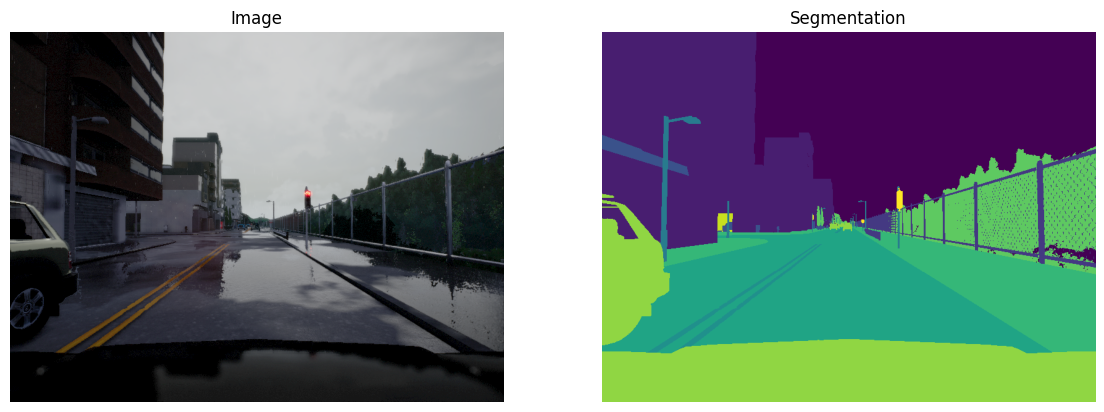

Image: (600, 800, 3) | Mask: (600, 800, 3) | Labels in this mask: [ 0  1  2  3  5  6  7  8  9 10 11 12]


In [93]:
img_dir  = os.path.join(DATA_DIR, 'CameraRGB')
mask_dir = os.path.join(DATA_DIR, MASK_FOLDER)

# keep only images that have a mask with the same name (skips duplicates like "x (1).png")
img_names  = set(f for f in os.listdir(img_dir)  if f.lower().endswith('.png'))
mask_names = set(f for f in os.listdir(mask_dir) if f.lower().endswith('.png'))
file_names = sorted(img_names & mask_names)
skipped = sorted(img_names ^ mask_names)
if skipped:
    print(f'Skipped {len(skipped)} file(s) without a matching pair, e.g.', skipped[:3])

image_list = [os.path.join(img_dir, f)  for f in file_names]
mask_list  = [os.path.join(mask_dir, f) for f in file_names]
print('Image/mask pairs used:', len(file_names))

N = 2
img, mask = imageio.imread(image_list[N]), imageio.imread(mask_list[N])
fig, arr = plt.subplots(1, 2, figsize=(14, 10))
arr[0].imshow(img);           arr[0].set_title('Image');        arr[0].axis('off')
arr[1].imshow(mask[:, :, 0]); arr[1].set_title('Segmentation'); arr[1].axis('off')
plt.show()
print('Image:', img.shape, '| Mask:', mask.shape, '| Labels in this mask:', np.unique(mask[:, :, 0]))

### 0.6 Build the data pipeline
- read the PNG files and scale image pixels to [0, 1],
- keep only the **red channel** of the mask (the class label),
- resize both to 96 × 128 with `nearest` interpolation, so labels stay whole numbers,
- keep **10 %** of the images aside as a **validation set** — the final boss is judged on images the model never trained on.

In [94]:
def process_path(image_path, mask_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=3)
    mask = mask[:, :, :1]          # the class label is stored in the red channel
    return img, mask

def preprocess(image, mask):
    input_image = tf.image.resize(image, (96, 128), method='nearest')
    input_mask  = tf.image.resize(mask,  (96, 128), method='nearest')
    return input_image, input_mask

pairs = list(zip(image_list, mask_list))
np.random.default_rng(7).shuffle(pairs)
n_val = max(1, len(pairs) // 10)
val_pairs, train_pairs = pairs[:n_val], pairs[n_val:]

def make_ds(p):
    ds = tf.data.Dataset.from_tensor_slices(([a for a, _ in p], [b for _, b in p]))
    return ds.map(process_path).map(preprocess)

train_ds, val_ds = make_ds(train_pairs), make_ds(val_pairs)
print('Training images:', len(train_pairs), '| Validation images:', len(val_pairs))

Training images: 900 | Validation images: 100


## 🧩 Level 1 — Shape puzzle (warm-up)

### How a U-Net works
A classification CNN ends with dense layers, which throw away *where* things are. Segmentation needs a label at every pixel, so U-Net is **fully convolutional** and shaped like a **U**:

1. **Encoder (contracting path)** — blocks of two 3×3 `same` convolutions with ReLU, then 2×2 max pooling. Each step **halves** height and width and **doubles** the filters.
2. **Bottleneck** — the deepest block, with no pooling.
3. **Decoder (expanding path)** — each step uses a **transposed convolution** to **double** height and width and **halve** the filters, concatenates the matching encoder output, then applies two 3×3 convolutions.
4. **Skip connections** — carry the encoder output at each level straight to the matching decoder level, giving back the fine detail lost by pooling.
5. **Output** — a 1×1 convolution maps the features at each pixel to **13 scores**, one per class.

```
cblock1 ──────────────skip──────────────► ublock9 → conv9 → conv10 (output)
   cblock2 ──────────skip──────────► ublock8
      cblock3 ──────skip──────► ublock7
         cblock4 ──skip──► ublock6
                 cblock5 (bottleneck)
```

### Your puzzle
For the puzzles, your test camera has its own image size and your U-Net its own `n_filters` (shown in your mission briefing). The real training in Level 5 uses 96 × 128 images and `n_filters = 32` for everyone. Run the cell to see your puzzle, then fill in the shapes.

In [95]:
show_level1()

🧩 SHAPE PUZZLE — input image 128 × 160 × 3, n_filters = 16, 13 classes

Fill in the (height, width, channels) of each block's output in the next cell:
  cblock1 … cblock4 → the SKIP output (before pooling)
  cblock5           → the bottleneck output
  ublock6 … ublock9 → the decoder block output
  output            → the final 1×1 convolution


In [96]:
# ANSWER: L1
# Write each shape as (height, width, channels)
L1_shapes = {
    'cblock1': (128, 160, 16),
    'cblock2': (64, 80, 32),
    'cblock3': (32, 40, 64),
    'cblock4': (16, 20, 128),
    'cblock5': (8, 10, 256),
    'ublock6': (16, 20, 128),
    'ublock7': (32, 40, 64),
    'ublock8': (64, 80, 32),
    'ublock9': (128, 160, 16),
    'output': (128, 160, 13),
}

In [97]:
check_level1(L1_shapes)

  ✅ cblock1  (128, 160, 16)
  ✅ cblock2  (64, 80, 32)
  ✅ cblock3  (32, 40, 64)
  ✅ cblock4  (16, 20, 128)
  ✅ cblock5  (8, 10, 256)
  ✅ ublock6  (16, 20, 128)
  ✅ ublock7  (32, 40, 64)
  ✅ ublock8  (64, 80, 32)
  ✅ ublock9  (128, 160, 16)
  ✅ output   (128, 160, 13)

Score: 10/10

🏁 LEVEL 1 COMPLETE!
🔑 Key for Level 2:  2E3172   → paste it into enter_key(2, '...')


In [127]:
hint(1)    # ← remove the # and run to get a hint (−2 game points)

💡 Hint 1/3 for Level 1 (−2 game points): Each encoder step halves H and W and doubles the channels.


## 🧩 Level 2 — Code order + Exercise 1: `conv_block`
Paste your Level 2 key 🔑 and run.

In [99]:
enter_key(2, '2E3172')

🔓 Level 2 unlocked!


### 2.1 Code-order puzzle
Before you write the encoder block, put it together like a puzzle. The lines are shuffled, and **two are traps**. Write the letters of the 6 correct lines in order, for example `"BHAEDC"`.

In [100]:
show_level2()

🧩 CODE-ORDER PUZZLE — build the body of conv_block.
Pick the 6 correct lines in the right order. Two lines are traps.

  A:  next_layer = MaxPooling2D(pool_size=(2, 2))(conv) if max_pooling else conv
  B:  conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(inputs)
  C:  skip_connection = conv
  D:  if dropout_prob > 0: conv = Dropout(dropout_prob)(conv)
  E:  return next_layer, skip_connection
  F:  conv = Dropout(dropout_prob)(inputs)
  G:  conv = Conv2D(n_filters, 3, activation='relu', padding='same', kernel_initializer='he_normal')(conv)
  H:  skip_connection = MaxPooling2D(pool_size=(2, 2))(conv)


In [101]:
# ANSWER: L2
L2_order = "BGDCAE"


In [102]:
check_level2_order(L2_order)

✅ Correct order: BGDCAE
Level 2 progress: order ✅   conv_block ⬜


### 2.2 Exercise 1 — `conv_block`
Each encoder block returns **two** tensors:
- `next_layer` — goes into the next encoder block,
- `skip_connection` — goes to the matching decoder block.

If `max_pooling=True`, `next_layer` is the pooling output and `skip_connection` is the tensor **before** pooling. Otherwise both are the same tensor.

**Implement it:**
1. Two **Conv2D** layers: `n_filters` filters, `kernel_size=3`, `activation='relu'`, `padding='same'`, `kernel_initializer='he_normal'`.
2. If `dropout_prob > 0`, a **Dropout** layer with rate `dropout_prob`.
3. If `max_pooling` is `True`, a **MaxPooling2D** layer with `pool_size=(2, 2)`.

In [103]:
# GRADED FUNCTION: conv_block
def conv_block(inputs=None, n_filters=32, dropout_prob=0, max_pooling=True):
    """
    Convolutional downsampling block
    Arguments:
        inputs -- Input tensor
        n_filters -- Number of filters for the convolutional layers
        dropout_prob -- Dropout probability
        max_pooling -- Use MaxPooling2D to reduce the spatial dimensions of the output volume
    Returns:
        next_layer, skip_connection -- Next layer and skip connection outputs
    """
    ### START CODE HERE
    conv = Conv2D(n_filters,
                  3,
                  activation='relu',
                  padding='same',
                  kernel_initializer='he_normal')(inputs)
    conv = Conv2D(n_filters,
                  3,
                  activation='relu',
                  padding='same',
                  kernel_initializer='he_normal')(conv)
    ### END CODE HERE

    if dropout_prob > 0:
        ### START CODE HERE
        conv = Dropout(dropout_prob)(conv)
        ### END CODE HERE

    if max_pooling:
        ### START CODE HERE
        next_layer = MaxPooling2D(pool_size=(2, 2))(conv)
        ### END CODE HERE
    else:
        next_layer = conv

    skip_connection = conv
    return next_layer, skip_connection

In [104]:
check_ex1()

✅ Block 1: all 3 layers match.
✅ Block 2: all 4 layers match.
Level 2 progress: order ✅   conv_block ✅

🏁 LEVEL 2 COMPLETE!
🔑 Key for Level 3:  2AAF6C   → paste it into enter_key(3, '...')


In [105]:
#hint(2)

## 🧩 Level 3 — Exercise 2: `upsampling_block` + parameter riddles
Paste your Level 3 key 🔑 and run.

In [106]:
enter_key(3, '2AAF6C')

🔓 Level 3 unlocked!


### 3.1 Exercise 2 — `upsampling_block`
The decoder block has two new parts:
- `up` — a **transposed convolution** that doubles height and width,
- `merge` — the **skip connection**: `up` concatenated with the matching encoder output.

Then two Conv2D layers with the same settings as in the encoder.

**Implement it:**
1. **Conv2DTranspose** on `expansive_input`: `n_filters` filters, kernel size `3`, `strides=(2, 2)`, `padding='same'`.
2. The concatenation is written for you: `concatenate([up, contractive_input], axis=3)`. Keep this order.
3. **Two Conv2D** layers: `n_filters`, kernel size `3`, `activation='relu'`, `padding='same'`, `kernel_initializer='he_normal'`.

In [107]:
# GRADED FUNCTION: upsampling_block
def upsampling_block(expansive_input, contractive_input, n_filters=32):
    """
    Convolutional upsampling block
    Arguments:
        expansive_input -- Input tensor from previous layer
        contractive_input -- Input tensor from previous skip layer
        n_filters -- Number of filters for the convolutional layers
    Returns:
        conv -- Tensor output
    """
    ### START CODE HERE
    up = Conv2DTranspose(
                 n_filters,    # number of filters
                 3,    # Kernel size
                 strides=(2, 2),
                 padding='same')(expansive_input)

    merge = concatenate([up, contractive_input], axis=3)
    conv = Conv2D(n_filters,   # Number of filters
                  3,   # Kernel size
                  activation='relu',
                  padding='same',
                  kernel_initializer='he_normal')(merge)
    conv = Conv2D(n_filters,   # Number of filters
                  3,   # Kernel size
                  activation='relu',
                  padding='same',
                  kernel_initializer='he_normal')(conv)
    ### END CODE HERE
    return conv

In [108]:
check_ex2()

✅ Upsampling block: all 4 layers match.
Level 3 progress: upsampling_block ✅   riddles ⬜


### 3.2 Parameter riddles
Work these out **by hand** for *your* U-Net — the numbers are different for every student.
- A convolution layer has *k × k × (input channels) × filters* weights, plus one bias per filter.
- Concatenation adds the channels of the two tensors.

In [109]:
show_level3()

🧩 PARAMETER RIDDLES — for YOUR U-Net (input 128 × 160 × 3, n_filters = 16, 13 classes)

R1: How many parameters does the Conv2DTranspose layer in ublock7 have?
R2: Right after the concatenation in ublock8, how many numbers does the tensor hold for one image?
    (height × width × channels)
R3: How many parameters does the final 1×1 convolution (conv10) have?


In [110]:
# ANSWER: L3
L3_answers = {
    'R1': 73792,
    'R2': 327680,
    'R3': 221,
}


In [111]:
check_level3(L3_answers)

  ✅ R1 = 73792
  ✅ R2 = 327680
  ✅ R3 = 221
Score: 10/10
Level 3 progress: upsampling_block ✅   riddles ✅

🏁 LEVEL 3 COMPLETE!
🔑 Key for Level 4:  B71D32   → paste it into enter_key(4, '...')


In [112]:
#hint(3)

## 🐞 Level 4 — Bug hunt + Exercise 3: `unet_model`
Paste your Level 4 key 🔑 and run.

In [113]:
enter_key(4, 'B71D32')

🔓 Level 4 unlocked!


### 4.1 Bug hunt
A junior engineer built a small 3-level U-Net (`mini_unet`) for a test camera — and it has **exactly 3 bugs**. Each line is numbered in a comment.

1. Run the cell. Read the error message (if any).
2. Fix the bugs **in place**, directly in the cell.
3. In the ANSWER cell, list the **line numbers** you fixed.

The checker tells you which layer is still wrong (type, shape, parameters or settings), but never shows the answer.

In [114]:
# GRADED FUNCTION: mini_unet
def mini_unet(input_size=(64, 64, 3), n_filters=16, n_classes=5):
    inputs = Input(input_size)                                                          # line 1
    cblock1 = conv_block(inputs, n_filters)                                             # line 2
    cblock2 = conv_block(cblock1[0], n_filters * 2)                                     # line 3
    cblock3 = conv_block(cblock2[0], n_filters * 4, dropout_prob=0.3, max_pooling=False) # line 4
    ublock4 = upsampling_block(cblock3[0], cblock2[1], n_filters * 2)                   # line 5
    ublock5 = upsampling_block(ublock4, cblock1[1], n_filters)                          # line 6
    outputs = Conv2D(n_classes, 1, padding='same', activation='linear')(ublock5)        # line 7
    return tf.keras.Model(inputs, outputs)                                              # line 8

try:
    mini_unet().summary()
except Exception as e:
    print("💥 mini_unet crashed:", type(e).__name__, "-", e)

Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_20      │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_142 (Conv2D) │ (None, 64, 64,    │        448 │ input_layer_20[0… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_143 (Conv2D) │ (None, 64, 64,    │      2,320 │ conv2d_142[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_30    │ (None, 32, 32,    │          0 │ conv2d_143[0][0]  │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_144 (Conv2D) │ (None, 32, 32,    │      4,640 │ max_pooling2d_30… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_145 (Conv2D) │ (None, 32, 32,    │      9,248 │ conv2d_144[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_31    │ (None, 16, 16,    │          0 │ conv2d_145[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_146 (Conv2D) │ (None, 16, 16,    │     18,496 │ max_pooling2d_31… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_147 (Conv2D) │ (None, 16, 16,    │     36,928 │ conv2d_146[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 16, 16,    │          0 │ conv2d_147[0][0]  │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_27 │ (None, 32, 32,    │     18,464 │ dropout_15[0][0]  │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_27      │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 64)               │            │ conv2d_145[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_148 (Conv2D) │ (None, 32, 32,    │     18,464 │ concatenate_27[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_149 (Conv2D) │ (None, 32, 32,    │      9,248 │ conv2d_148[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_28 │ (None, 64, 64,    │      4,624 │ conv2d_149[0][0]  │
│ (Conv2DTranspose)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_28      │ (None, 64, 64,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 32)               │            │ conv2d_143[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_150 (Conv2D) │ (None, 64, 64,    │      4,624 │ concatenate_28[0

 Total params: 129,909 (507.46 KB)

 Trainable params: 129,909 (507.46 KB)

 Non-trainable params: 0 (0.00 B)

In [115]:
# ANSWER: L4
L4_bug_lines = {3, 5, 7}      # e.g. {1, 2, 8}

In [116]:
check_bug_hunt(L4_bug_lines)

  ✅ bug lines you reported: [3, 5, 7]
  ✅ mini_unet repaired — every layer matches.
Score: 10/10
Level 4 progress: bug hunt ✅   unet_model ⬜


In [117]:
#hint(4)

### 4.2 Exercise 3 — `unet_model`
Now chain everything into the full U-Net. The output has **13 channels**, one per class.

**Encoder:**
1. `cblock1`: a conv block on `inputs` with `n_filters`.
2. Each next block takes the **first** output `[0]` (after pooling) of the previous block and **doubles** the filters: `n_filters*2`, `*4`, `*8`, `*16`.
3. `cblock4`: `dropout_prob=0.3`.
4. `cblock5` (bottleneck): `dropout_prob=0.3` and `max_pooling=False`.

**Decoder:**
1. `ublock6`: `expansive_input = cblock5[0]`, `contractive_input = cblock4[1]`, filters `n_filters*8`.
2. Each next block takes the previous decoder output and the **second** output `[1]` (before pooling) of the matching encoder block. **Halve** the filters each step: `*4`, `*2`, `*1`.

**Output:**
- `conv9` is given.
- `conv10`: Conv2D with `n_classes` filters, kernel size `1`, `padding='same'`, **no activation** (the loss works on raw scores).

In [118]:
# GRADED FUNCTION: unet_model
def unet_model(input_size=(96, 128, 3), n_filters=32, n_classes=13):
    """
    Unet model
    Arguments:
        input_size -- Input shape
        n_filters -- Number of filters for the convolutional layers
        n_classes -- Number of output classes
    Returns:
        model -- tf.keras.Model
    """
    inputs = Input(input_size)
    ### START CODE HERE
    cblock1 = conv_block(inputs, n_filters)
    cblock2 = conv_block(cblock1[0], n_filters * 2)
    cblock3 = conv_block(cblock2[0], n_filters * 4)
    cblock4 = conv_block(cblock3[0], n_filters * 8, dropout_prob=0.3)
    cblock5 = conv_block(cblock4[0], n_filters * 16, dropout_prob=0.3, max_pooling=False)
    ### END CODE HERE

    ### START CODE HERE
    ublock6 = upsampling_block(cblock5[0], cblock4[1], n_filters * 8)
    ublock7 = upsampling_block(ublock6, cblock3[1], n_filters * 4)
    ublock8 = upsampling_block(ublock7, cblock2[1], n_filters * 2)
    ublock9 = upsampling_block(ublock8, cblock1[1], n_filters)
    ### END CODE HERE

    conv9 = Conv2D(n_filters, 3, activation='relu', padding='same',
                   kernel_initializer='he_normal')(ublock9)

    ### START CODE HERE
    conv10 = Conv2D(n_classes, 1, padding='same')(conv9)
    ### END CODE HERE

    return tf.keras.Model(inputs=inputs, outputs=conv10)

In [119]:
check_ex3()

✅ U-Net: all 34 layers match.
Total parameters: 8,640,141
Level 4 progress: bug hunt ✅   unet_model ✅

🏁 LEVEL 4 COMPLETE!
🔑 Key for Level 5:  8D0430   → paste it into enter_key(5, '...')


## 👾 Level 5 — The final boss
Paste your Level 5 key 🔑 and run.

In [120]:
enter_key(5, '8D0430')

🔓 Level 5 unlocked!


### 5.1 The boss: real roads
Your U-Net must now see roads it has **never trained on**. Train it, then face the boss: the **validation pixel accuracy** must reach the target (printed by the engine, 0.85 by default).

**Loss function:** the model outputs 13 scores per pixel, and the mask stores **one integer label per pixel** (0–12). **Sparse categorical cross-entropy** compares integer labels with class scores directly — no one-hot encoding needed. `from_logits=True` means the model outputs raw scores and the loss applies softmax itself.

Training takes about 1 minute per epoch or less on a T4 GPU.

In [121]:
EPOCHS = 15
BATCH_SIZE = 32
BUFFER_SIZE = 500

tf.keras.utils.set_random_seed(1)
train_dataset = train_ds.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
val_dataset = val_ds.cache().batch(BATCH_SIZE)

unet = unet_model((96, 128, 3))
unet.compile(optimizer='adam',
             loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
             metrics=['accuracy'])
model_history = unet.fit(train_dataset, epochs=EPOCHS, validation_data=val_dataset)

Epoch 1/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 48s 695ms/step - accuracy: 0.3880 - loss: 1.7586 - val_accuracy: 0.5716 - val_loss: 1.3304
Epoch 2/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 134ms/step - accuracy: 0.6476 - loss: 1.0821 - val_accuracy: 0.7445 - val_loss: 0.7793
Epoch 3/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 132ms/step - accuracy: 0.7727 - loss: 0.6828 - val_accuracy: 0.8049 - val_loss: 0.6063
Epoch 4/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step - accuracy: 0.8194 - loss: 0.5590 - val_accuracy: 0.8239 - val_loss: 0.5426
Epoch 5/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 135ms/step - accuracy: 0.8492 - loss: 0.4779 - val_accuracy: 0.8456 - val_loss: 0.5020
Epoch 6/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 135ms/step - accuracy: 0.8690 - loss: 0.4271 - val_accuracy: 0.8653 - val_loss: 0.4369
Epoch 7/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 135ms/step - accuracy: 0.8919 - loss: 0.3576 - val_accuracy: 0.8909 - val_loss: 0.3506
Epoch 8/15
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 136ms/step - accuracy: 0.9048 - loss: 0.3133 - val_accuracy: 0

In [122]:
# ⚔️ Face the boss — do not edit this cell
val_acc = report_boss(unet, val_dataset)

🎯 Validation pixel accuracy: 0.9304   (target 0.85)
🏆 BOSS DEFEATED — the car can see the road!

🏁 LEVEL 5 COMPLETE!
BOSS_RESULT::{"id": "22208066", "val_acc": 0.9304}


### 5.2 Training curve

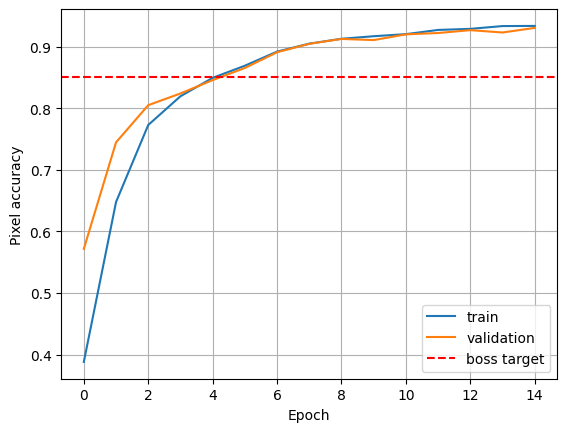

In [123]:
plt.plot(model_history.history['accuracy'], label='train')
plt.plot(model_history.history['val_accuracy'], label='validation')
plt.axhline(BOSS_TARGET, ls='--', c='r', label='boss target')
plt.xlabel('Epoch'); plt.ylabel('Pixel accuracy'); plt.legend(); plt.grid(True); plt.show()

### 5.3 See through the car's eyes
`tf.argmax` over the 13 class scores picks the most likely class at each pixel — the predicted mask.

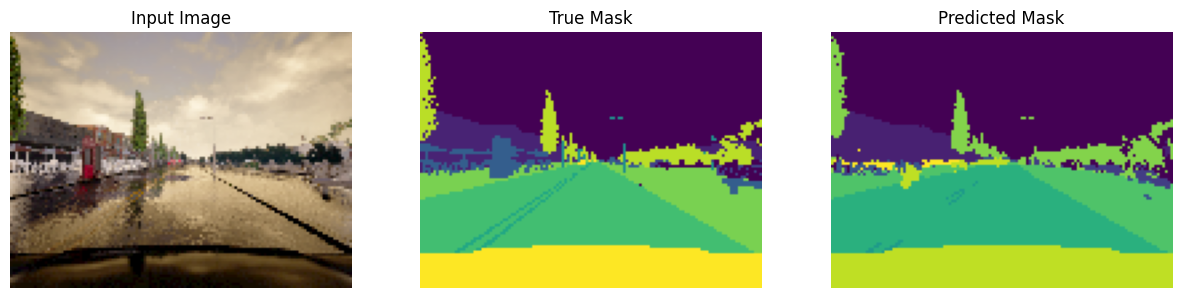

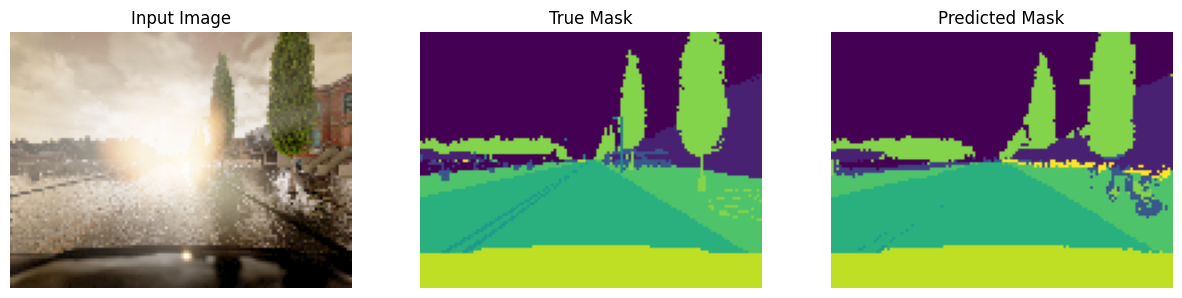

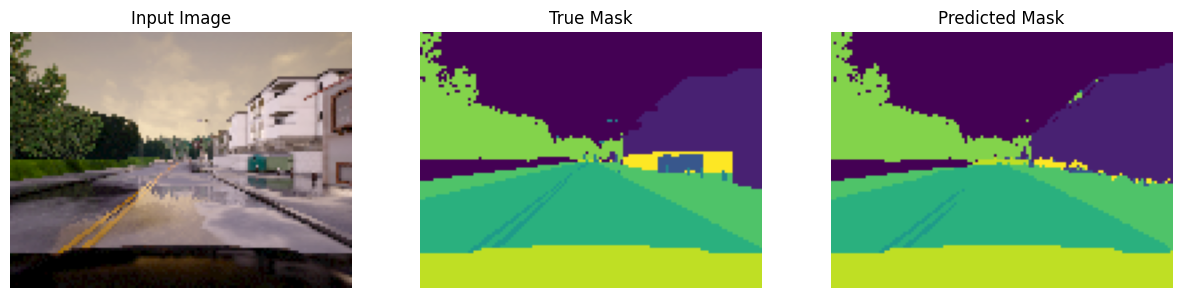

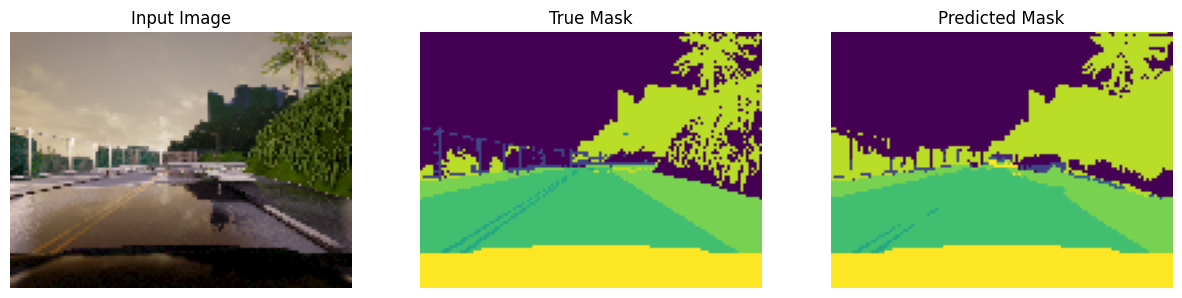

In [124]:
def display(display_list):
    plt.figure(figsize=(15, 15))
    title = ['Input Image', 'True Mask', 'Predicted Mask']
    for i in range(len(display_list)):
        plt.subplot(1, len(display_list), i + 1)
        plt.title(title[i])
        plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
        plt.axis('off')
    plt.show()

def create_mask(pred_mask):
    pred_mask = tf.argmax(pred_mask, axis=-1)
    pred_mask = pred_mask[..., tf.newaxis]
    return pred_mask[0]

for image, mask in val_dataset.unbatch().batch(1).take(4):
    display([image[0], mask[0], create_mask(unet.predict(image, verbose=0))])

In [125]:
#hint(5)

## 🏁 Scoreboard

In [128]:
scoreboard()

🏁 SCOREBOARD — driver 22208066
  Level 1 · Shape puzzle          10 / 10
  Level 2 · Code-order puzzle      5 / 5
  Level 2 · conv_block            15 / 15
  Level 3 · upsampling_block      15 / 15
  Level 3 · Parameter riddles     10 / 10
  Level 4 · Bug hunt              10 / 10
  Level 4 · unet_model            20 / 20
  Level 5 · Final boss            15 / 15
----------------------------------------------------------
  Challenge points            100 / 100
  Hints used: 1 (−2)   Levels skipped: 0 (−0)
  🎮 GAME SCORE                98
  Badges: 🏆 Boss Slayer  🐞 Bug Hunter  📐 Shape Master
Your official grade is computed by your instructor's grader from your submitted notebook.


## Debrief (discussed in class — not auto-graded)
Answer each question in 2–3 sentences.

**D1.** What did the bug on line 3 of `mini_unet` do, and why did the error appear on a different line?

*Your answer:*   
The bug in line 3 used the skip connection instead of the pooled output, which means the image size stayed the same instead of getting smaller. The error appeared later in the decoder because the layers had different sizes and couldn't be combined correctly.

**D2.** What would happen to the predicted masks without skip connections? Why?

*Your answer:*   
Without skip connections, the model would lose important details from the original image, so the predicted masks would be less accurate, especially around the edges of objects. This is because pooling makes the image smaller and removes some details, while skip connections help the model recover them.

**D3.** Pixel accuracy can be high even when the car misses pedestrians. Why? Suggest a better metric.

*Your answer:*   
Pixel accuracy can still be high even if the model misses pedestrians because they take up a small part of the image compared to things like roads and buildings. A better metric would be per-class IoU because it checks how accurately each class is predicted instead of only looking at the overall accuracy.

## Submission — GitHub link
1. Make sure **every cell has been run** and the outputs are visible, including the boss result and the scoreboard.
2. In Colab, choose *File → Save a copy in GitHub*.
3. Select your repository and name the file `CS4085_Lab7_<YourStudentID>.ipynb`. Keep **Include a link to Colab** ticked, then click **OK**.
4. Open the file on GitHub and check that the outputs are shown. Copy the link from the browser's address bar.
5. Submit **only this link** on Blackboard.

**Important**
- Your repository must be one your instructor can open (public, or private with your instructor added as a collaborator).
- **Do not rename the graded functions or delete the first line of any graded or answer cell** — the grader looks for them.
- Do not change the notebook after the deadline; the version on GitHub at the deadline is graded.